In [2]:
# easy -riya
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Create circuit with 1 input qubit and 1 output qubit
qc = QuantumCircuit(2, 1)

# Prepare output qubit in |-> state
qc.x(1)
qc.h(1)

# Apply Hadamard to input qubit
qc.h(0)

# Constant oracle f(x) = 0
# No gates are required

# Apply final Hadamard
qc.h(0)

# Measure input qubit
qc.measure(0, 0)

# Simulate circuit
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement results:", counts)

if '0' in counts:
    print("Result: 0 (Constant function)")
else:
    print("Result: 1 (Balanced function)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.4 MB/s eta 0:00:00
Measurement results: {'0': 1024}
Result: 0 (Constant function)


In [3]:
#medium
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Create circuit with 1 input qubit and 1 output qubit
qc = QuantumCircuit(2, 1)

# Prepare output qubit in |-> state
qc.x(1)
qc.h(1)

# Apply Hadamard to input qubit
qc.h(0)

# Balanced oracle: f(x) = x
qc.cx(0, 1)

# Apply final Hadamard
qc.h(0)

# Measure input qubit
qc.measure(0, 0)

# Simulate circuit
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement results:", counts)

if '1' in counts:
    print("Result: 1 (Balanced function)")
else:
    print("Result: 0 (Constant function)")

Measurement results: {'1': 1024}
Result: 1 (Balanced function)


In [4]:
#hard
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch_algorithm(function_type):
    # 1 input qubit, 1 output qubit, 1 classical bit
    qc = QuantumCircuit(2, 1)

    # Prepare output qubit in |-> state
    qc.x(1)
    qc.h(1)

    # Apply Hadamard to input qubit
    qc.h(0)

    # Dynamically select oracle
    if function_type == "constant":
        pass  # f(x) = 0

    elif function_type == "balanced":
        qc.cx(0, 1)  # f(x) = x

    else:
        raise ValueError("Choose 'constant' or 'balanced'")

    # Final Hadamard and measurement
    qc.h(0)
    qc.measure(0, 0)

    return qc

# Select the function type
function_type = "balanced"

qc = deutsch_algorithm(function_type)
qc.draw("text")

# Run simulation
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Function type:", function_type)
print("Measurement results:", counts)

if "0" in counts:
    print("Result: Constant function")
else:
    print("Result: Balanced function")

Function type: balanced
Measurement results: {'1': 1024}
Result: Balanced function


Error angle: 0.00 radians
Counts: {'1': 2000}
Correct classification: 100.00%

Error angle: 0.05 radians
Counts: {'0': 1, '1': 1999}
Correct classification: 99.95%

Error angle: 0.10 radians
Counts: {'0': 4, '1': 1996}
Correct classification: 99.80%

Error angle: 0.20 radians
Counts: {'0': 22, '1': 1978}
Correct classification: 98.90%

Error angle: 0.30 radians
Counts: {'0': 44, '1': 1956}
Correct classification: 97.80%



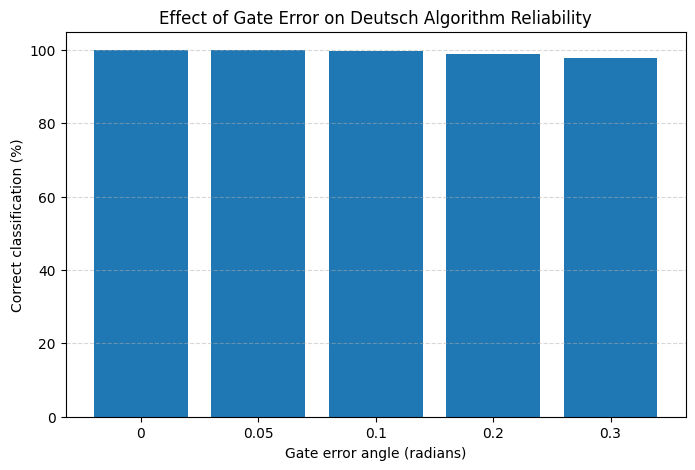

In [5]:
#challenge
!pip install qiskit qiskit-aer matplotlib

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

errors = [0, 0.05, 0.10, 0.20, 0.30]
correct_results = []

for error in errors:
    qc = QuantumCircuit(2, 1)

    # Prepare output qubit in |-> state
    qc.x(1)
    qc.h(1)

    # Initial Hadamard on input
    qc.h(0)

    # Balanced oracle: f(x) = x
    qc.cx(0, 1)

    # Imperfect final Hadamard: H followed by a small RY error
    qc.h(0)
    qc.ry(error, 0)

    qc.measure(0, 0)

    result = simulator.run(qc, shots=2000).result()
    counts = result.get_counts()

    # For a balanced function, correct result is 1
    correct = counts.get('1', 0) / 2000 * 100
    correct_results.append(correct)

    print(f"Error angle: {error:.2f} radians")
    print(f"Counts: {counts}")
    print(f"Correct classification: {correct:.2f}%\n")

# Plot reliability
plt.figure(figsize=(8, 5))
plt.bar([str(e) for e in errors], correct_results)
plt.xlabel("Gate error angle (radians)")
plt.ylabel("Correct classification (%)")
plt.title("Effect of Gate Error on Deutsch Algorithm Reliability")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()